# 02 First optimization round
Prerequisite: finish notebook 01 using the same RUN_NAME. Optimize LR regularization,
RF tree complexity and XGBoost tree complexity. Select by mean validation ROC-AUC.


In [1]:
# If the kernel is missing dependencies, uncomment the next line, execute it,
# then restart the kernel before continuing. This notebook never auto-installs packages.
# %pip install -r requirements-notebooks.txt


In [2]:
from pathlib import Path
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import xgboost
from IPython.display import display
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import cross_validate, GridSearchCV

# Set this only when Jupyter is launched outside the project.
PROJECT_ROOT = None  # Example: Path(r"/path/to/final project")
if PROJECT_ROOT is None:
    PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                         if (p / "data/processed/caroline_cleaned version/cardio_train_80.csv").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Set PROJECT_ROOT to the project folder containing data/ and notebooks/.")
PROJECT_ROOT = Path(PROJECT_ROOT).expanduser().resolve()
NOTEBOOK_DIR = PROJECT_ROOT / "notebooks/model_training_jupyter"
sys.path.insert(0, str(NOTEBOOK_DIR))
from training_utils import (
    FEATURES, METRICS, SEED, MODEL_NAMES, load_development, build_pipeline,
    scorers, select_auc, begin_stage, collect_cv, save_model_result,
    finish_stage, load_stage, comparison_plots, compare_history,
)

# Use the SAME name in all three notebooks. Use a new name for a fresh rerun.
RUN_NAME = "seven_features_run_01"
RUN_DIR = NOTEBOOK_DIR / "runs" / RUN_NAME
print("Project:", PROJECT_ROOT)
print("Run output:", RUN_DIR)
print("scikit-learn:", sklearn.__version__, "| XGBoost:", xgboost.__version__)


Project: /Users/liujueshan/Desktop/comp4145/final project
Run output: /Users/liujueshan/Desktop/comp4145/final project/notebooks/model_training_jupyter/runs/seven_features_run_01
scikit-learn: 1.9.1 | XGBoost: 3.4.1


Seven inputs: age, gender, BMI, systolic BP, diastolic BP, cholesterol and glucose.
Categorical encoding produces nine model columns. Logistic regression scales numeric inputs
inside each training fold; tree models do not scale them. The five grouped folds are identical
across models and stages. All classification metrics use `score >= 0.5`.

Tables report **five-fold validation means**. ROC/confusion plots use pooled out-of-fold (OOF)
predictions, so pooled AUC may differ slightly from the mean fold AUC.


In [3]:
# No test CSV is loaded. Continuous inputs are restored to original units.
ctx = load_development(PROJECT_ROOT)
X, y, cv = ctx["X"], ctx["y"], ctx["cv"]
assert X.shape == (54855, 7)
assert "cardio" not in FEATURES and "id" not in FEATURES
print("Input features:", FEATURES)
display(pd.DataFrame(X, columns=FEATURES).head())
display(pd.Series(y, name="cardio").value_counts().rename_axis("label").to_frame("records"))
display(pd.DataFrame([
    {"fold": i, "training_records": len(train), "validation_records": len(valid)}
    for i, (train, valid) in enumerate(cv, 1)
]))


Input features: ['age_years', 'gender', 'bmi', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc']


,age_years,gender,bmi,ap_hi,ap_lo,cholesterol,gluc
0,59.890486,2.0,25.306932,120.0,80.0,1.0,1.0
1,57.746749,1.0,34.963580,135.0,90.0,2.0,1.0
2,42.187543,1.0,48.223448,180.0,120.0,2.0,1.0
3,49.744011,2.0,20.957274,80.0,70.0,1.0,1.0
4,57.549624,1.0,29.136316,120.0,90.0,2.0,1.0


,records
label,
0,27718
1,27137


,fold,training_records,validation_records
0,1,43884,10971
1,2,43883,10972
2,3,43885,10970
3,4,43884,10971
4,5,43884,10971


In [4]:
previous = load_stage(RUN_DIR, "01_baseline", ctx)
PARAMETER_GRIDS = {
    "logistic_regression": {"C": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]},
    "random_forest": {
        "max_depth": [6, 10, 14],
        "min_samples_leaf": [10, 30, 60],
    },
    "xgboost": {
        "max_depth": [2, 3, 4],
        "min_child_weight": [1, 5, 10],
    },
}
grid_table = pd.DataFrame([
    {"Model": name, "Parameter": key, "Candidate values": repr(values)}
    for name, grid in PARAMETER_GRIDS.items()
    for key, values in grid.items()
])
display(grid_table.style.hide(axis='index').set_properties(**{'text-align': 'left', 'white-space': 'normal', 'overflow-wrap': 'anywhere'}))
STAGE_DIR = begin_stage(RUN_DIR, "02_round1", ctx)
SCORING = scorers()
results = {}


Model,Parameter,Candidate values
logistic_regression,C,"[0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]"
random_forest,max_depth,"[6, 10, 14]"
random_forest,min_samples_leaf,"[10, 30, 60]"
xgboost,max_depth,"[2, 3, 4]"
xgboost,min_child_weight,"[1, 5, 10]"


## Search directions
- Logistic regression: vary C (regularization strength).
- Random forest: reduce unrestricted tree complexity using depth and minimum samples per leaf.
- XGBoost: vary depth and minimum child weight (a Hessian-sum constraint, not a literal sample count).
There are 7 + 9 + 9 = 25 candidates, each evaluated in the same five folds.


In [5]:
for name, grid in PARAMETER_GRIDS.items():
    print("Grid search:", MODEL_NAMES[name], flush=True)
    # All unchanged parameters come from the preceding NOTEBOOK RUN.
    # Historical winners are not hard-coded.
    parameters = previous[name]["parameters"].copy()
    pipeline = build_pipeline(name, parameters)
    search = GridSearchCV(
        estimator=pipeline,
        param_grid={"classifier__" + k: values for k, values in grid.items()},
        scoring=SCORING, refit=select_auc, cv=cv,
        return_train_score=True, n_jobs=1, error_score="raise", verbose=1,
    )
    with warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        search.fit(X, y)

    selected = parameters.copy()
    selected.update({k.split("__", 1)[1]: value for k, value in search.best_params_.items()})
    print("Selected parameters:", selected)
    print("Selection criterion: highest mean validation ROC-AUC")
    grid_table = pd.DataFrame(search.cv_results_)
    display_columns = ["params", "rank_test_roc_auc"] + [
        "mean_test_" + metric for metric in METRICS
    ] + ["mean_train_roc_auc", "mean_train_accuracy"]
    # In sklearn's grid table, 'test' means CV VALIDATION folds, not the final test CSV.
    display(grid_table[display_columns].sort_values("rank_test_roc_auc").round(6))

    # Refit the selected configuration in the same folds to export its OOF scores.
    # This replays the selected CV configuration; it is not an independent new evaluation.
    with warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        selected_cv = cross_validate(
            build_pipeline(name, selected), X, y, cv=cv, scoring=SCORING,
            return_train_score=True, return_estimator=True,
            n_jobs=1, error_score="raise",
        )
    evaluation = collect_cv(
        selected_cv["estimator"], ctx,
        reference=search.cv_results_, best_index=search.best_index_,
    )
    # GridSearchCV already refitted best_estimator_ on the full development set.
    save_model_result(
        STAGE_DIR, name, search.best_estimator_, selected,
        evaluation, ctx, search_results=search.cv_results_,
    )
    results[name] = evaluation
    del selected_cv, search


Grid search: Logistic Regression


Fitting 5 folds for each of 7 candidates, totalling 35 fits


Selected parameters: {'C': 100.0, 'solver': 'lbfgs', 'max_iter': 1000, 'class_weight': None, 'random_state': 4145}
Selection criterion: highest mean validation ROC-AUC


,params,rank_test_roc_auc,mean_test_roc_auc,mean_test_accuracy,mean_test_precision,mean_test_recall,mean_test_f1,mean_test_specificity,mean_test_average_precision,mean_train_roc_auc,mean_train_accuracy
5,{'classifier__C': 100.0},1,0.791059,0.727573,0.756898,0.661974,0.706241,0.791796,0.769796,0.791178,0.727632
6,{'classifier__C': 1000.0},2,0.791058,0.727573,0.756898,0.661974,0.706241,0.791796,0.769796,0.791178,0.727632
4,{'classifier__C': 10.0},3,0.791058,0.727573,0.756898,0.661974,0.706241,0.791796,0.769796,0.791178,0.727632
3,{'classifier__C': 1.0},4,0.791057,0.727591,0.756888,0.662048,0.706278,0.791760,0.769794,0.791178,0.727618
2,{'classifier__C': 0.1},5,0.791042,0.727536,0.756834,0.661974,0.706213,0.791724,0.769761,0.791166,0.727605
1,{'classifier__C': 0.01},6,0.790799,0.727573,0.755843,0.663780,0.706808,0.790029,0.769418,0.790924,0.727536
0,{'classifier__C': 0.001},7,0.787687,0.726096,0.751023,0.667723,0.706914,0.783246,0.766514,0.787793,0.725978


Grid search: Random Forest


Fitting 5 folds for each of 9 candidates, totalling 45 fits


... (2 outputs left out)

Grid search: XGBoost


Fitting 5 folds for each of 9 candidates, totalling 45 fits


Selected parameters: {'n_estimators': 300, 'max_depth': 3, 'min_child_weight': 5, 'learning_rate': 0.05, 'subsample': 1.0, 'colsample_bytree': 1.0, 'reg_lambda': 1.0, 'objective': 'binary:logistic', 'eval_metric': 'logloss', 'tree_method': 'hist', 'random_state': 4145, 'n_jobs': 4}
Selection criterion: highest mean validation ROC-AUC


,params,rank_test_roc_auc,mean_test_roc_auc,mean_test_accuracy,mean_test_precision,mean_test_recall,mean_test_f1,mean_test_specificity,mean_test_average_precision,mean_train_roc_auc,mean_train_accuracy
4,"{'classifier__max_depth': 3, 'classifier__min_...",1,0.800579,0.735794,0.753483,0.692523,0.721713,0.778159,0.781710,0.806964,0.739295
3,"{'classifier__max_depth': 3, 'classifier__min_...",2,0.800539,0.735849,0.754020,0.691712,0.721519,0.779061,0.781640,0.807167,0.739281
5,"{'classifier__max_depth': 3, 'classifier__min_...",3,0.800516,0.735357,0.753134,0.691860,0.721189,0.777942,0.781438,0.806794,0.739349
7,"{'classifier__max_depth': 4, 'classifier__min_...",4,0.800332,0.734938,0.755774,0.685890,0.719118,0.782957,0.781503,0.812549,0.742056
6,"{'classifier__max_depth': 4, 'classifier__min_...",5,0.800194,0.734883,0.755654,0.685927,0.719086,0.782813,0.781557,0.813248,0.742439
8,"{'classifier__max_depth': 4, 'classifier__min_...",6,0.800067,0.734992,0.755477,0.686590,0.719366,0.782380,0.780759,0.812017,0.741664
2,"{'classifier__max_depth': 2, 'classifier__min_...",7,0.799325,0.734336,0.750201,0.694108,0.721062,0.773721,0.779274,0.802423,0.736264
0,"{'classifier__max_depth': 2, 'classifier__min_...",8,0.799322,0.734099,0.749974,0.693813,0.720798,0.773541,0.779272,0.802468,0.736223
1,"{'classifier__max_depth': 2, 'classifier__min_...",9,0.799292,0.734154,0.750143,0.693665,0.720796,0.773793,0.779037,0.802407,0.736159


In [6]:
comparison = finish_stage(STAGE_DIR, ctx, previous.keys())


## Compare the first-round selected models


In [7]:
display(comparison[[
    "model", "status", "training_auc", "roc_auc", "training_accuracy",
    "accuracy", "precision", "recall", "f1", "specificity", "average_precision"
]].round(6))


,model,status,training_auc,roc_auc,training_accuracy,accuracy,precision,recall,f1,specificity,average_precision
0,logistic_regression,trained,0.791178,0.791059,0.727632,0.727573,0.756898,0.661974,0.706241,0.791796,0.769796
1,random_forest,trained,0.815468,0.800122,0.743478,0.736432,0.760839,0.681468,0.718956,0.790245,0.781407
2,xgboost,trained,0.806964,0.800579,0.739295,0.735794,0.753483,0.692523,0.721713,0.778159,0.781710


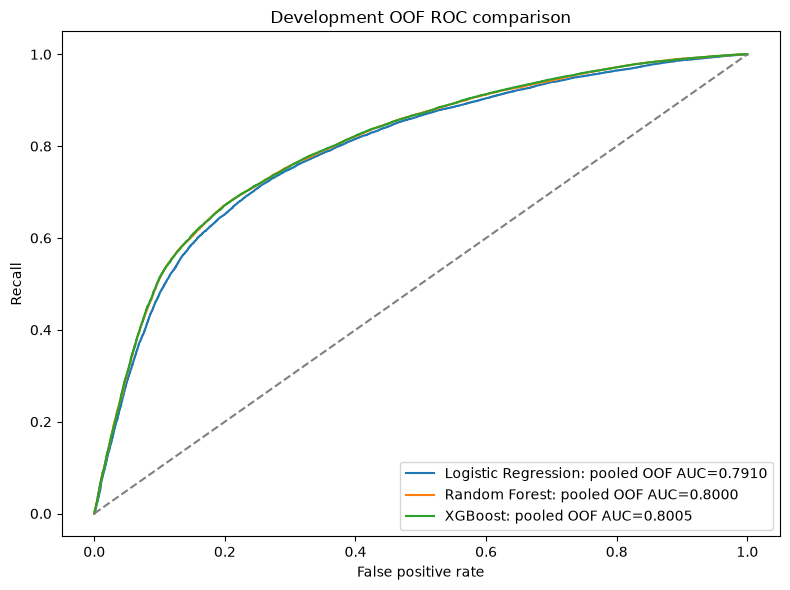

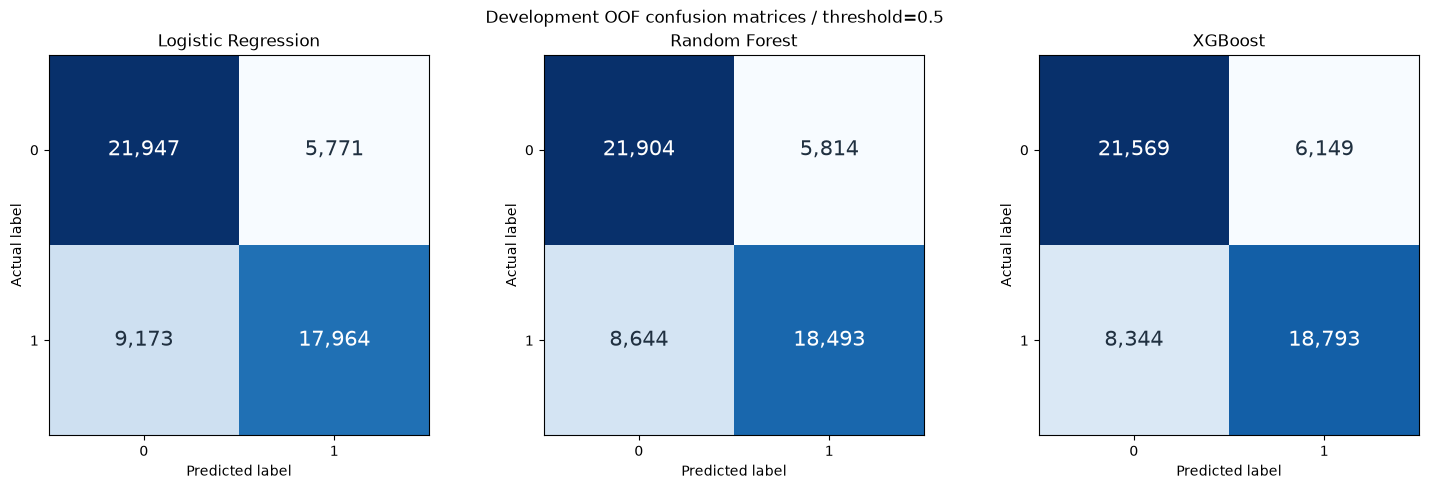

In [8]:
# Models trained on each validation record's own training fold generated these scores.
# The separately saved final model is fitted on all development records.
comparison_plots(results, ctx, STAGE_DIR)


In [9]:
history = compare_history(RUN_DIR, ["01_baseline", "02_round1"])
display(history[["stage", "model", "training_accuracy", *METRICS]].round(6))
print("Saved first-round output:", STAGE_DIR)
print("Next: open 03_optimization_round2.ipynb with the same RUN_NAME.")


,stage,model,training_accuracy,roc_auc,accuracy,precision,recall,f1,specificity,average_precision
0,01_baseline,logistic_regression,0.727618,0.791057,0.727591,0.756888,0.662048,0.706278,0.791760,0.769794
1,01_baseline,random_forest,0.999713,0.763978,0.704822,0.705061,0.693408,0.699177,0.715997,0.746882
2,01_baseline,xgboost,0.739281,0.800539,0.735849,0.754020,0.691712,0.721519,0.779061,0.781640
3,02_round1,logistic_regression,0.727632,0.791059,0.727573,0.756898,0.661974,0.706241,0.791796,0.769796
4,02_round1,random_forest,0.743478,0.800122,0.736432,0.760839,0.681468,0.718956,0.790245,0.781407
5,02_round1,xgboost,0.739295,0.800579,0.735794,0.753483,0.692523,0.721713,0.778159,0.781710


Saved first-round output: /Users/liujueshan/Desktop/comp4145/final project/notebooks/model_training_jupyter/runs/seven_features_run_01/02_round1
Next: open 03_optimization_round2.ipynb with the same RUN_NAME.
